In [824]:
# Bengio-style MLP language model: predicts the next letter from the previous 3
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [825]:
words = open('names.txt','r').read().splitlines()

In [826]:
words[:8]


['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [827]:
len(words)

32033

In [828]:
# letter <-> number mappings; '.' is index 0 and marks both start and end of a name
chars = sorted(list(set(''.join(words))))
stoi =  {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {s:i for i,s in stoi.items()}

In [829]:
# hyperparameters: change these here, nothing below has a hard-coded copy
seed = 2147483647       # for reproducibility
block_size = 3          # how many previous letters the model sees
emb_dim = 30            # numbers per letter in the embedding
n_hidden = 200          # neurons in the hidden layer
batch_size = 32         # examples per training step
n_steps = 60000         # steps per run of the training loop (re-running the loop continues from current weights)
learning_rate = 0.1   # change between training phases; the loop below reads this value
n_inputs = block_size * emb_dim   # derived: size of the flattened embedding fed to the hidden layer


In [830]:
# each example: 3 previous letters (X) -> the next letter (Y)
def build_dataset(words):
    X,Y= [],[]
    
    for w in words:
        # print(w)
        context=[0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->',itos[ix])
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X,Y

# split by whole names: 80% train, 10% dev (tune settings), 10% test (use once at the end)
# NOTE: this cell shuffles `words` in place, so re-running it alone gives a different split
import random 
shuffled = words.copy()     
random.seed(42)
random.shuffle(shuffled)
n1= int(0.8*len(shuffled))
n2 = int(0.9*len(shuffled))
Xtr, Ytr = build_dataset(shuffled[:n1])
Xdev, Ydev = build_dataset(shuffled[n1:n2])
Xte, Yte = build_dataset(shuffled[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [831]:
# MLP setup: C = embedding table, W1/b1 = hidden layer, W2/b2 = output layer (27 scores, one per letter)
# plain unscaled random init: the first loss is high, which is fine at this size
g = torch.Generator().manual_seed(seed) # for reproducibility
C = torch.randn([27, emb_dim], generator = g)
W1 = torch.randn((n_inputs, n_hidden), generator = g)
b1 = torch.randn(n_hidden, generator = g)
W2 = torch.randn((n_hidden, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True   # without this, loss.backward() has nothing to differentiate

In [832]:
# total number of weights the model learns
sum(p.nelement() for p in parameters)

24437

In [833]:
# learning-rate sweep (optional): try rates 10**-3 .. 10**0, one per step, and plot loss vs rate
# lre = torch.linspace(-3,0,1000)
# lrs = 10**lre
# print(lrs)

In [834]:
# run once before a fresh training; skip it to keep one loss curve across several phases
lri = []
lossi = []
steps = []
gb = torch.Generator().manual_seed(seed + 1)

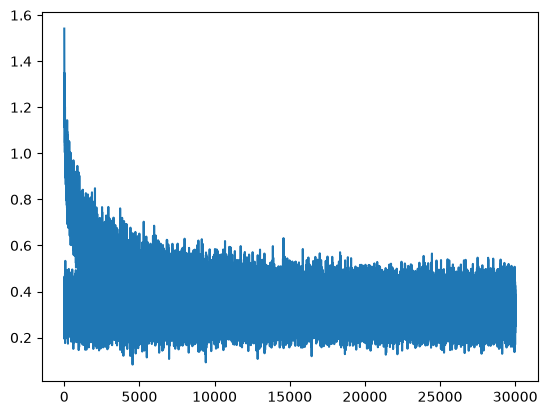

In [850]:

for i in range(n_steps):
    # mini-batch: pick batch_size random training examples
    ix = torch.randint(0,Xtr.shape[0],(batch_size,),generator=gb)
    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, n_inputs) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # backward pass: clear old gradients, then compute new ones
    for p in parameters:
        p.grad = None
    loss.backward()
    # update: step each weight against its gradient
    # lr = lrs[i]   # use this line for the sweep
    # 3 lrs for consective runs
    lr = 0.005
    lr = 0.01
    lr = learning_rate
    for p in parameters:
        p.data += -lr * p.grad

    # track stats (log10 of loss so the curve is easier to read)
    # lri.append(lre[i].item())
    lossi.append(loss.log10().item())
    steps.append(i)

plt.plot(steps, lossi)


In [851]:
# eval on the full training set (not a mini-batch, so it is stable)
#   compare with dev: a small gap is normal, a large gap means memorizing
emb = C[Xtr] # (N, block_size, emb_dim)
h = torch.tanh(emb.view(-1, n_inputs) @ W1 + b1) # (N, n_hidden)
logits = h @ W2 + b2 # (N, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.0762, grad_fn=<NllLossBackward0>)

In [852]:
# eval on the full dev set: names the weights never trained on
emb = C[Xdev] # (N, block_size, emb_dim)
h = torch.tanh(emb.view(-1, n_inputs) @ W1 + b1) # (N, n_hidden)
logits = h @ W2 + b2 # (N, 27)
loss = F.cross_entropy(logits, Ydev)
loss



tensor(2.1529, grad_fn=<NllLossBackward0>)

In [853]:
# eval on the full test set: run once, at the end; do not tune settings on this number
emb = C[Xte] # (N, block_size, emb_dim)
h = torch.tanh(emb.view(-1, n_inputs) @ W1 + b1) # (N, n_hidden)
logits = h @ W2 + b2 # (N, 27)
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.1517, grad_fn=<NllLossBackward0>)

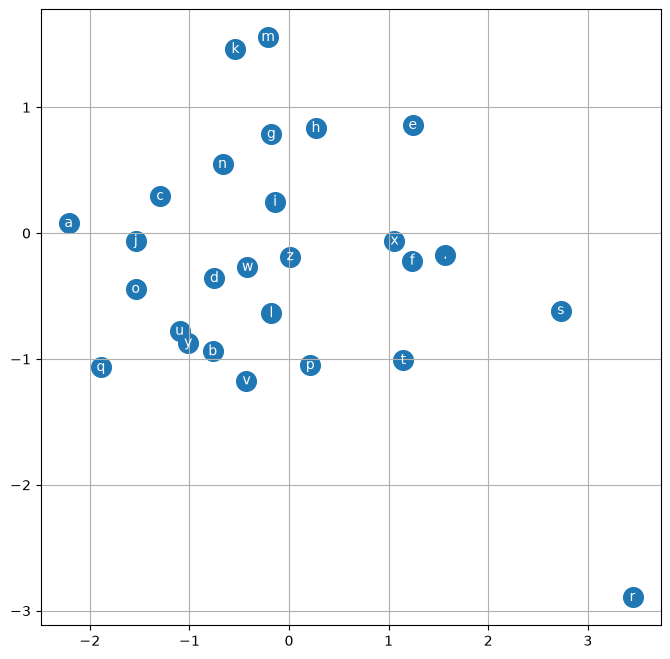

In [793]:
# first 2 of the emb_dim embedding numbers per letter; a partial view when emb_dim > 2
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt. text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [713]:
# generation: sample new names with a fixed seed
g= torch.Generator().manual_seed(seed + 10)

In [714]:
# start from '...' and sample one letter at a time until '.' (end of name)
for _ in range(20):
    out=[]
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(-1, n_inputs) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs,num_samples=1,generator=g).item()
        context = context[1:]+[ix]
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))




carmanfaylen.
kitzimrek.
tate.
skanden.
jazzett.
deliah.
jareei.
ner.
kentceriin.
kaleigh.
ham.
joce.
quintin.
lilea.
jadiq.
wazelo.
dearynix.
kael.
dura.
med.
